# Double Descent in Linear Models
**Assignment 4 — Strelskaya Sofya 47912A**

Double-descent test-error curve for linear least squares with $n$ (number of
training points) fixed and $d$ (number of features / parameters) varied, and compares it with ridge regression.

Dataset: Synthetic, noisy linear labels
How $d$ is varied: first $d$ of $D$ Gaussian features (Section 2)

Dataset: Real: UCI *Appliances Energy Prediction*
How $d$ is varied: (a) first $d$ raw features, random order; (b) $N$ random Fourier features (Section 3)

Gradient descent vs closed form (4.1) and effect of label noise (4.2). Section 5 compares datasets.

Learning algorithms: minimum-norm least squares, ridge, gradient descent, random Fourier
features, cross-validation
NumPy - used for linear algebra primitives (matrix products, SVD) and pandas only to read the CSV. 

the real dataset is split **chronologically** (with a one-day gap) because it is a time series.

**Reproducibility.** All randomness comes from one master seed. Dataset `energydata_complete.csv` (https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction)

Total runtime is ~ 5-10 mins

In [67]:
# 0. Setup
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MASTER_SEED = 2026
DATA_PATH = Path("energydata_complete.csv")
FIG_DIR = Path("figures");  FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results");  RES_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10, "legend.fontsize": 8})
C_TRAIN, C_TEST, C_NORM = "#E07B39", "#1F77B4", "#555555"
RIDGE_COLORS = ["#9ecae1", "#6baed6", "#3182bd", "#08519c"]


def rng_for(name):
    """Independent, reproducible random generator for each experiment (same result whatever cell order)."""
    key = [ord(c) for c in name]
    return np.random.default_rng(np.random.SeedSequence([MASTER_SEED, *key]))


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150)

T0 = time.time()

## 1. Algorithms

All models are linear, $\hat y = x^\top w$, trained with the squared loss $\frac1n\|Xw-y\|^2$.
Let $X = U\,\mathrm{diag}(s)\,V^\top$ be the thin SVD of the $n\times d$ training matrix.

**Least squares.** When there are fewer features than data points (d < n), there's one best fit, the normal regression. When there are more features than points (d > n), infinitely many weight vectors fit the training data perfectly. Following the paper, we pick the one with the smallest size (norm). We compute it with the SVD instead of the textbook formula (XᵀX)⁻¹Xᵀy, because XᵀX can't be inverted when d > n and is unstable near d = n.

**Ridge.** Same as least squares plus a penalty λ‖w‖² for large weights. In SVD terms, instead of dividing by very small singular values, which is what causes the explosion, ridge dampens them. One SVD gives the answer for every λ.

**Gradient descent.** Repeatedly take a small step downhill on the loss. The step size is 1/L, where L is the largest eigenvalue of XᵀX/n; this is the standard choice that guarantees convergence.

**Cross-validated ridge.** λ is chosen by 5-fold cross-validation, using only the training data.

In [68]:
def thin_svd(X):
    return np.linalg.svd(X, full_matrices=False)


def fit_least_squares(X, y, rcond=None, svd=None):
    """Minimum-l2-norm least-squares solution w = X^+ y via the thin SVD.
    `svd` can be a precomputed thin_svd(X), so one decomposition serves several solvers."""
    n, d = X.shape
    U, s, Vt = thin_svd(X) if svd is None else svd
    if rcond is None:
        rcond = max(n, d) * np.finfo(X.dtype).eps
    keep = s > rcond * s[0]
    return Vt[keep].T @ ((U[:, keep].T @ y) / s[keep])


def fit_ridge_path(X, y, lambdas, svd=None):
    """Ridge solutions for every lambda in `lambdas` (objective (1/n)||Xw-y||^2 + lam ||w||^2).
    Returns an array of shape (len(lambdas), d)."""
    n = X.shape[0]
    U, s, Vt = thin_svd(X) if svd is None else svd
    Uty = U.T @ y
    lambdas = np.atleast_1d(lambdas)
    shrink = s[None, :] / (s[None, :] ** 2 + n * lambdas[:, None])   # (L, r)
    return (shrink * Uty[None, :]) @ Vt                                # (L, d)


def fit_ridge(X, y, lam):
    return fit_ridge_path(X, y, [lam])[0]


def fit_gradient_descent(X, y, n_iter, w0=None, record_at=()):
    """Full-batch GD on (1/2n)||Xw - y||^2 with step 1/L. Returns final w and {iteration: w} snapshots."""
    n, d = X.shape
    w = np.zeros(d) if w0 is None else np.array(w0, dtype=float)
    L = np.linalg.norm(X, 2) ** 2 / n            # largest eigenvalue of X^T X / n
    eta = 1.0 / L
    record_at = set(record_at)
    snaps = {}
    for t in range(1, n_iter + 1):
        w -= eta * (X.T @ (X @ w - y)) / n
        if t in record_at:
            snaps[t] = w.copy()
    return w, snaps


def fit_ridge_cv(X, y, lambdas, folds):
    """Pick lambda by K-fold CV (folds = list of validation index arrays, all inside the training set),
    then refit on the full training set. Returns (w, chosen_lambda)."""
    lambdas = np.asarray(lambdas)
    cv_err = np.zeros(len(lambdas))
    all_idx = np.arange(len(y))
    for val in folds:
        tr = np.setdiff1d(all_idx, val)
        W = fit_ridge_path(X[tr], y[tr], lambdas)          # (L, d)
        cv_err += ((X[val] @ W.T - y[val][:, None]) ** 2).mean(axis=0)
    best = lambdas[np.argmin(cv_err)]
    return fit_ridge(X, y, best), best


def mse(y_true, y_pred):
    return float(np.mean((y_true - y_pred) ** 2))

### 1.1 Correctness checks
Each solver is checked against an independent computation (NumPy's `lstsq`, which is only used here as a reference,
and the normal equations). The last check verifies the theory used in Section 4.1: gradient descent started at w_0
converges to X^+y + (I - X^+X)\,w_0, i.e. to the minimum-norm solution when w_0=0.

In [69]:
def run_unit_tests():
    rng = rng_for("unit-tests")
    for n, d in [(40, 10), (40, 40), (20, 60)]:
        X, y = rng.standard_normal((n, d)), rng.standard_normal(n)
        w = fit_least_squares(X, y)
        w_ref = np.linalg.lstsq(X, y, rcond=None)[0]          # reference only
        assert np.allclose(w, w_ref, atol=1e-8), (n, d)
        if d >= n:
            assert mse(y, X @ w) < 1e-20, "min-norm LS must interpolate when d >= n"
        for lam in [1e-3, 0.1, 10.0]:
            w_r = fit_ridge(X, y, lam)
            w_ne = np.linalg.solve(X.T @ X + n * lam * np.eye(d), X.T @ y)
            assert np.allclose(w_r, w_ne, atol=1e-8), (n, d, lam)
    # ridge -> min-norm LS as lambda -> 0 (over-parameterised case)
    X, y = rng.standard_normal((20, 60)), rng.standard_normal(20)
    assert np.allclose(fit_ridge(X, y, 1e-12), fit_least_squares(X, y), atol=1e-5)
    # GD from 0 -> min-norm; GD from w0 -> min-norm + projection of w0 on null(X)
    X, y = rng.standard_normal((30, 80)), rng.standard_normal(30)
    w_mn = fit_least_squares(X, y)
    w_gd0, _ = fit_gradient_descent(X, y, n_iter=20000)
    assert np.linalg.norm(w_gd0 - w_mn) / np.linalg.norm(w_mn) < 1e-6
    w0 = rng.standard_normal(80)
    w_gdr, _ = fit_gradient_descent(X, y, n_iter=20000, w0=w0)
    P_null = np.eye(80) - np.linalg.pinv(X) @ X                  # reference only
    assert np.linalg.norm(w_gdr - (w_mn + P_null @ w0)) / np.linalg.norm(w_gdr) < 1e-6
    # CV picks a lambda from the grid and returns a vector of the right size
    folds = np.array_split(np.arange(30), 5)
    w_cv, lam = fit_ridge_cv(X, y, np.logspace(-4, 1, 6), folds)
    assert w_cv.shape == (80,) and lam in np.logspace(-4, 1, 6)
    print("All unit tests passed.")

run_unit_tests()

All unit tests passed.


### 1.2 Experiment helpers
For every model size we record training MSE, test MSE and $\|w\|_2$ over many independent trials.
Near the interpolation threshold the test error is heavy-tailed (a single trial can be 100× the others), so the
plots show the **median** across trials with the 25–75 % band; the mean is also saved to `results/`

In [70]:
def summarise(records, key):
    """records: list of dicts with keys 'size', 'trial', metrics... -> DataFrame of median/q25/q75/mean per size."""
    df = pd.DataFrame(records)
    g = df.groupby(key)
    out = pd.DataFrame({"size": list(g.groups.keys())}).set_index("size")
    for m in [c for c in df.columns if c not in (key, "trial")]:
        out[f"{m}_median"] = g[m].median()
        out[f"{m}_q25"] = g[m].quantile(0.25)
        out[f"{m}_q75"] = g[m].quantile(0.75)
        out[f"{m}_mean"] = g[m].mean()
    return out.reset_index()


def plot_band(ax, x, s, metric, color, label, **kw):
    ax.plot(x, s[f"{metric}_median"], color=color, label=label, **kw)
    ax.fill_between(x, s[f"{metric}_q25"], s[f"{metric}_q75"], color=color, alpha=0.18, lw=0)


def dense_grid(n, max_size, extra=()):
    """Grid of model sizes that is dense around the interpolation threshold n."""
    g = set(np.unique(np.round(np.geomspace(1, max_size, 30)).astype(int)))
    g |= set(range(max(1, int(0.8 * n)), min(max_size, int(1.2 * n)) + 1, max(1, n // 50)))
    g |= {n - 1, n, n + 1} | set(extra)
    return np.array(sorted(x for x in g if 1 <= x <= max_size))

## 2. Synthetic dataset

**Data generating process**
**Inputs:** each data point is a list of 500 random numbers, drawn from a standard normal distribution (bell curve, mean 0, variance 1). So there are 500 possible features
**Labels:** each label is a weighted sum of those 500 numbers plus random noise: y = ±0.78·x₁ ± 0.39·x₂ ± 0.26·x₃ ± … + noise. The weights are the "true" coefficients β*, the answer the model is trying to learn.
The weights get smaller: feature 1 has the biggest weight, feature 2 half that, feature 3 a third, and so on (weight ∝ 1/j). Each weight gets a random + or − sign. They're scaled so the total signal has variance 1.
**Noise:** normal with standard deviation σ = 0.5, so variance 0.25. The signal is 4 times stronger than the noise (variance 1 vs 0.25), which is what "signal-to-noise ratio 4" means.

**How model uses the data**
- model with d features only sees the first d of the 500 numbers. It's blind to the rest
- features it can't see still affect y, so from the model's point of view they look like extra noise.
- Because the weights shrink, the first few features carry most of the information. Adding them helps a lot at first, but more features add little real information while the model starts fitting noise. That gives the classic U-shape for d < n: error drops, hits a minimum, then rises

**Running experiment**
- 100 training points (n = 100); d goes from 1 to 500
- Each trial makes a new test set of 5,000 points to measure the error accurately
- experiment is repeated 40 times, each with new random signs, training data and test data, so the results don't depend on one lucky or unlucky draw
- Everything has mean zero by construction, so the model needs no intercept (no "+ b" term).

In [71]:
SYN = dict(n=100, D=500, sigma=0.5, n_test=5000, n_trials=40)


def make_synthetic(rng, n, n_test, D, sigma, decay=1.0):
    """beta_j = +-j^(-decay), normalised to ||beta|| = 1 (decay=0: signal spread evenly over all D features)."""
    beta = rng.choice([-1.0, 1.0], size=D) / np.arange(1, D + 1) ** decay
    beta /= np.linalg.norm(beta)
    X = rng.standard_normal((n + n_test, D))
    y = X @ beta + sigma * rng.standard_normal(n + n_test)
    return X[:n], y[:n], X[n:], y[n:], beta


def synthetic_sweep(sigma, sizes, lambdas=(), n_trials=None, seed_name="syn", cv=False, decay=1.0):
    rng = rng_for(f"{seed_name}-{sigma}-{decay}")
    n, D, n_test = SYN["n"], SYN["D"], SYN["n_test"]
    n_trials = n_trials or SYN["n_trials"]
    rec = []
    for t in range(n_trials):
        Xtr, ytr, Xte, yte, _ = make_synthetic(rng, n, n_test, D, sigma, decay)
        folds = np.array_split(rng.permutation(n), 5)
        for d in sizes:
            A, B = Xtr[:, :d], Xte[:, :d]
            svd = thin_svd(A)
            w = fit_least_squares(A, ytr, svd=svd)
            r = dict(d=d, trial=t, train=mse(ytr, A @ w), test=mse(yte, B @ w), norm=np.linalg.norm(w))
            if len(lambdas):
                for lam, wl in zip(lambdas, fit_ridge_path(A, ytr, np.array(lambdas), svd=svd)):
                    r[f"test_ridge_{lam:g}"] = mse(yte, B @ wl)
                    r[f"train_ridge_{lam:g}"] = mse(ytr, A @ wl)
            if cv:
                wc, lam_c = fit_ridge_cv(A, ytr, CV_LAMBDAS, folds)
                r["test_ridge_cv"], r["lambda_cv"] = mse(yte, B @ wc), lam_c
            r["test_null"] = mse(yte, np.zeros_like(yte))      # predict 0 (the true mean)
            rec.append(r)
    return summarise(rec, "d")


RIDGE_LAMBDAS = [1e-4, 1e-3, 1e-2, 1e-1]
CV_LAMBDAS = np.logspace(-6, 1, 29)
SYN_SIZES = dense_grid(SYN["n"], SYN["D"])

t = time.time()
syn = synthetic_sweep(SYN["sigma"], SYN_SIZES, lambdas=RIDGE_LAMBDAS, cv=True)
syn.to_csv(RES_DIR / "synthetic_main.csv", index=False)
print(f"synthetic sweep: {len(SYN_SIZES)} sizes x {SYN['n_trials']} trials in {time.time()-t:.1f}s")

synthetic sweep: 47 sizes x 40 trials in 24.1s


### 2.1 Least squares: double descent
Top: training and test MSE (log scale). Bottom: norm of the learned coefficients. The dashed line marks the
interpolation threshold $d=n$, where the training error reaches zero.

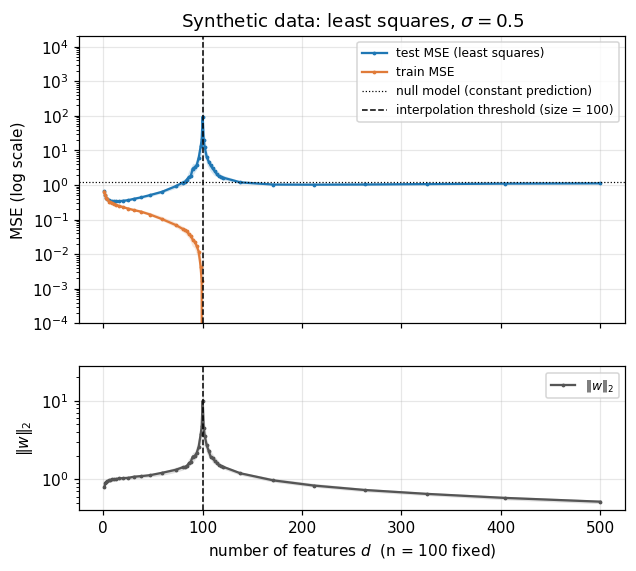

In [72]:
def plot_double_descent(s, n, xlabel, title, fname, null_level=None, extra_hlines=(), threshold=None):
    thr = n if threshold is None else threshold
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.4, 5.6), sharex=True,
                                   gridspec_kw={"height_ratios": [2, 1]})
    x = s["size"]
    plot_band(ax1, x, s, "test", C_TEST, "test MSE (least squares)", marker=".", ms=3)
    plot_band(ax1, x, s, "train", C_TRAIN, "train MSE", marker=".", ms=3)
    if null_level is not None:
        ax1.axhline(null_level, color="k", lw=0.8, ls=":", label="null model (constant prediction)")
    for y0, lab, st in extra_hlines:
        ax1.axhline(y0, color="grey", lw=0.9, ls=st, label=lab)
    ax1.set_yscale("log"); ax1.set_ylabel("MSE (log scale)"); ax1.set_title(title)
    ax1.set_ylim(bottom=max(ax1.get_ylim()[0], 1e-4))
    plot_band(ax2, x, s, "norm", C_NORM, r"$\|w\|_2$", marker=".", ms=3)
    ax2.set_yscale("log"); ax2.set_ylabel(r"$\|w\|_2$"); ax2.set_xlabel(xlabel)
    ax1.axvline(thr, color="k", ls="--", lw=1, label=f"interpolation threshold (size = {thr})")
    ax2.axvline(thr, color="k", ls="--", lw=1)
    ax1.legend(loc="best")
    ax2.legend(loc="upper right")
    savefig(fig, fname); plt.show()


plot_double_descent(syn, SYN["n"], "number of features $d$  (n = 100 fixed)",
                    "Synthetic data: least squares, $\\sigma=0.5$", "fig1_synthetic_ls",
                    null_level=syn["test_null_median"].iloc[0])

In [73]:
def key_numbers(s, n, label, threshold=None):
    """Classical optimum (size < threshold), value at the threshold, value at the largest model."""
    thr = n if threshold is None else threshold
    under = s[s["size"] < thr]
    i_best = under["test_median"].idxmin()
    at_n = s.loc[s["size"] == thr, "test_median"].item()
    last = s.iloc[-1]
    row = dict(dataset=label,
               best_underparam_size=int(s.loc[i_best, "size"]), best_underparam_test=s.loc[i_best, "test_median"],
               test_at_threshold=at_n, largest_size=int(last["size"]), test_at_largest=last["test_median"],
               overall_best_size=int(s.loc[s["test_median"].idxmin(), "size"]),
               overall_best_test=s["test_median"].min())
    return row

summary_rows = [key_numbers(syn, SYN["n"], "synthetic (sigma=0.5)")]
pd.DataFrame(summary_rows)

,dataset,best_underparam_size,best_underparam_test,test_at_threshold,largest_size,test_at_largest,overall_best_size,overall_best_test
0,synthetic (sigma=0.5),11,0.33496,95.037079,500,1.114987,11,0.33496


### 2.2 Comparison with ridge
Fixed $\lambda$ values, plus ridge with $\lambda$ selected by 5-fold CV **on the training set** for every $d$

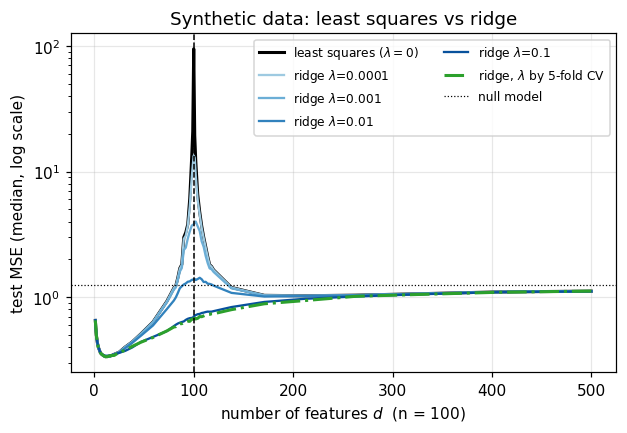

Test MSE (median) at selected d:
 size  test_median  test_ridge_0.0001_median  test_ridge_0.001_median  test_ridge_0.01_median  test_ridge_0.1_median  test_ridge_cv_median
   90        2.994                     2.901                    2.368                   1.260                  0.640                 0.629
  100       95.037                    13.403                    3.798                   1.389                  0.701                 0.670
  110        3.008                     2.948                    2.515                   1.318                  0.752                 0.708
  500        1.115                     1.115                    1.115                   1.115                  1.111                 1.116


In [74]:
def plot_ridge(s, n, xlabel, title, fname, lambdas, null_level=None, threshold=None):
    thr = n if threshold is None else threshold
    fig, ax = plt.subplots(figsize=(6.4, 4))
    x = s["size"]
    ax.plot(x, s["test_median"], color="k", lw=2, label="least squares ($\\lambda=0$)")
    for lam, col in zip(lambdas, RIDGE_COLORS):
        ax.plot(x, s[f"test_ridge_{lam:g}_median"], color=col, label=f"ridge $\\lambda$={lam:g}")
    if "test_ridge_cv_median" in s:
        ax.plot(x, s["test_ridge_cv_median"], color="#2ca02c", lw=2, ls="-.", label="ridge, $\\lambda$ by 5-fold CV")
    if null_level is not None:
        ax.axhline(null_level, color="k", lw=0.8, ls=":", label="null model")
    ax.axvline(thr, color="k", ls="--", lw=1)
    ax.set_yscale("log"); ax.set_xlabel(xlabel); ax.set_ylabel("test MSE (median, log scale)")
    ax.set_title(title); ax.legend(ncol=2)
    savefig(fig, fname); plt.show()


plot_ridge(syn, SYN["n"], "number of features $d$  (n = 100)", "Synthetic data: least squares vs ridge",
           "fig2_synthetic_ridge", RIDGE_LAMBDAS, null_level=syn["test_null_median"].iloc[0])

cols = ["size", "test_median"] + [f"test_ridge_{l:g}_median" for l in RIDGE_LAMBDAS] + ["test_ridge_cv_median"]
print("Test MSE (median) at selected d:")
print(syn[syn["size"].isin([10, 50, 90, 100, 110, 200, 500])][cols].round(3).to_string(index=False))

### 2.3 Numerical note: singular-value cutoff at $d=n$
Exactly at the threshold the smallest singular values of X are tiny, and the peak height depends on which
of them the solver keeps. Pruning small singular values is itself a (spectral-cutoff) regulariser

In [75]:
rng = rng_for("rcond")
rows = []
for t in range(SYN["n_trials"]):
    Xtr, ytr, Xte, yte, _ = make_synthetic(rng, SYN["n"], SYN["n_test"], SYN["D"], SYN["sigma"])
    A, B = Xtr[:, :SYN["n"]], Xte[:, :SYN["n"]]
    s_min = np.linalg.svd(A, compute_uv=False)[-1]
    for rc in [None, 1e-6, 1e-3, 1e-2, 5e-2]:
        w = fit_least_squares(A, ytr, rcond=rc)
        rows.append(dict(rcond="default (max(n,d)*eps)" if rc is None else rc, trial=t,
                         test=mse(yte, B @ w), s_min_over_s_max=s_min / np.linalg.svd(A, compute_uv=False)[0]))
rc_tab = pd.DataFrame(rows).groupby("rcond", sort=False).agg(test_median=("test", "median"),
                                                             smin_ratio_median=("s_min_over_s_max", "median"))
rc_tab.to_csv(RES_DIR / "rcond_sensitivity.csv"); rc_tab

,test_median,smin_ratio_median
rcond,,
"default (max(n,d)*eps)",57.580591,0.001821
0.000001,57.580591,0.001821
0.001,50.028496,0.001821
0.01,6.641675,0.001821
0.05,1.604594,0.001821


### 2.4 Does the over-parameterised model beat the classical optimum?
With decaying coefficients (above) the first few features carry most of the signal, so a small model is already
good and the second descent does not get below the classical minimum. We repeat the experiment with the signal
spread **evenly** over all $D$ features ($\beta^*_j = \pm 1/\sqrt D$, "decay = 0"): now every feature is weak, a
small model misses most of the signal, and the best test error is reached in the over-parameterised regime

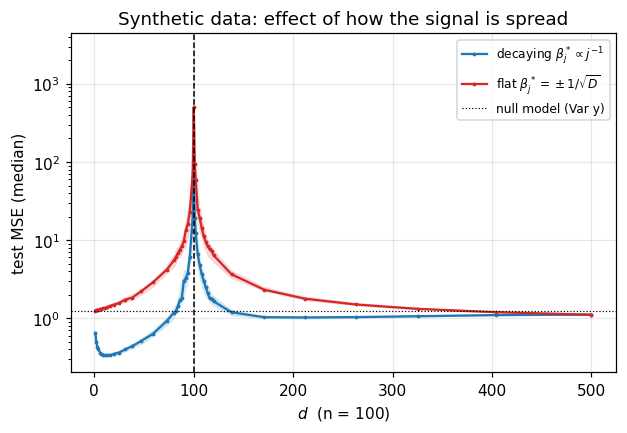

,dataset,best_underparam_size,best_underparam_test,test_at_threshold,largest_size,test_at_largest,overall_best_size,overall_best_test
0,synthetic (sigma=0.5),11,0.3350,95.0371,500,1.1150,11,0.3350
1,synthetic flat beta (sigma=0.5),1,1.2572,498.6070,500,1.1076,500,1.1076


In [76]:
syn_flat = synthetic_sweep(SYN["sigma"], SYN_SIZES, decay=0.0)
syn_flat.to_csv(RES_DIR / "synthetic_flat_beta.csv", index=False)

fig, ax = plt.subplots(figsize=(6.4, 4))
for s_, lab, col in [(syn, r"decaying $\beta^*_j\propto j^{-1}$", C_TEST), (syn_flat, r"flat $\beta^*_j=\pm1/\sqrt{D}$", "#d62728")]:
    plot_band(ax, s_["size"], s_, "test", col, lab, marker=".", ms=3)
ax.axhline(1 + SYN["sigma"] ** 2, color="k", ls=":", lw=0.8, label="null model (Var y)")
ax.axvline(SYN["n"], color="k", ls="--", lw=1)
ax.set_yscale("log"); ax.set_xlabel("$d$  (n = 100)"); ax.set_ylabel("test MSE (median)")
ax.set_title("Synthetic data: effect of how the signal is spread"); ax.legend()
savefig(fig, "fig2b_synthetic_signal_spread"); plt.show()
summary_rows.append(key_numbers(syn_flat, SYN["n"], "synthetic flat beta (sigma=0.5)"))
pd.DataFrame(summary_rows).round(4)

## 3. Real dataset: UCI Appliances Energy Prediction

19 735 readings taken every 10 minutes for about 4.5 months (Candanedo et al., 2017). Target: energy used by
appliances (Wh). Pre-processing choices:

* **Target:** $\log(\text{Appliances})$. The raw target is strongly right-skewed (occasional spikes up to ~1 000 Wh),
  and squared error on the raw scale would be dominated by a handful of spikes.
* **Features (28):** `lights`, the 18 indoor temperature/humidity sensors, the 6 weather-station variables, plus
  $\sin/\cos$ of the time of day and a weekend indicator derived from the timestamp.
  `rv1` and `rv2` are dropped: the dataset authors added them as pure random noise.
* **Chronological split:** the first 70 % of the period is the training pool, the last 30 % is the test set, with a
  one-day gap between them. A random split would put almost identical consecutive readings on both sides (leakage).
* **Per trial**, $n$ training points are drawn at random from the training pool. Standardisation (mean/std) and the
  target mean are computed on those $n$ points only, then applied to the test set.

19735 rows, 28 features: ['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'tod_sin', 'tod_cos', 'weekend']
period: 2016-01-11 17:00:00  ->  2016-05-27 18:00:00
training pool: 13814 rows (until 2016-04-16 15:17); test: 5777 rows (from 2016-04-17 15:17)


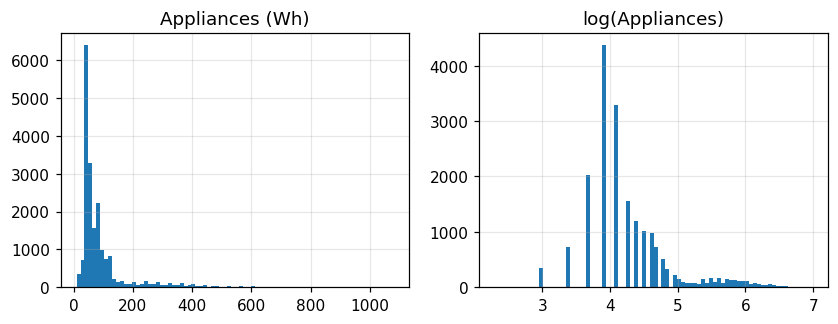

In [77]:
def load_energy(path=DATA_PATH):
    if not Path(path).exists():
        raise FileNotFoundError(
            f"{path} not found. Download the zip from "
            "https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction and put "
            "energydata_complete.csv next to this notebook.")
    df = pd.read_csv(path)
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)
    assert df.notna().all().all(), "unexpected missing values"
    assert (df["Appliances"] > 0).all(), "log target needs positive values"
    minutes = df["date"].dt.hour * 60 + df["date"].dt.minute
    df["tod_sin"] = np.sin(2 * np.pi * minutes / 1440)
    df["tod_cos"] = np.cos(2 * np.pi * minutes / 1440)
    df["weekend"] = (df["date"].dt.dayofweek >= 5).astype(float)
    feature_cols = [c for c in df.columns if c not in ("date", "Appliances", "rv1", "rv2")]
    return df, feature_cols


energy, FEATURES = load_energy()
print(f"{len(energy)} rows, {len(FEATURES)} features: {FEATURES}")
print(f"period: {energy['date'].min()}  ->  {energy['date'].max()}")

# chronological split with a one-day gap
t_split = energy["date"].min() + 0.7 * (energy["date"].max() - energy["date"].min())
pool_mask = energy["date"] < t_split
test_mask = energy["date"] >= t_split + pd.Timedelta(days=1)
X_pool, y_pool = energy.loc[pool_mask, FEATURES].to_numpy(float), np.log(energy.loc[pool_mask, "Appliances"].to_numpy(float))
X_test_raw, y_test_raw = energy.loc[test_mask, FEATURES].to_numpy(float), np.log(energy.loc[test_mask, "Appliances"].to_numpy(float))
print(f"training pool: {pool_mask.sum()} rows (until {t_split:%Y-%m-%d %H:%M}); "
      f"test: {test_mask.sum()} rows (from {t_split + pd.Timedelta(days=1):%Y-%m-%d %H:%M})")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(energy["Appliances"], bins=80, color=C_TEST); axes[0].set_title("Appliances (Wh)")
axes[1].hist(np.log(energy["Appliances"]), bins=80, color=C_TEST); axes[1].set_title("log(Appliances)")
savefig(fig, "fig0_energy_target"); plt.show()


def standardise_from_train(Xtr, Xte):
    mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
    sd = np.where(sd > 1e-12, sd, 1.0)              # constant column in a small sample -> leave it at 0
    return (Xtr - mu) / sd, (Xte - mu) / sd


def energy_trial_data(rng, n):
    idx = rng.choice(len(y_pool), size=n, replace=False)
    Xtr, Xte = standardise_from_train(X_pool[idx], X_test_raw)
    y_mean = y_pool[idx].mean()
    return Xtr, y_pool[idx] - y_mean, Xte, y_test_raw - y_mean, idx

### 3.1 (a) Raw features: fix $n$, vary $d$ directly
This is the most literal version of the task: a plain linear model on the first $d$ of the 28 real features.
Because there are only 28 features, $n$ must be small to see both regimes; we use $n=12$.
The order in which features enter is random in each trial (so no feature ordering is favoured), and we
average over 300 trials because each trial is very noisy with 12 points.


**Where is the threshold here?** Features and target are centred with the training means, which is equivalent to
fitting an intercept. Centring removes one degree of freedom: the centred $n\times d$ matrix has rank at most
$n-1$, so the model interpolates already at $d = n-1 = 11$ (i.e. $d+1 = n$ parameters counting the intercept).
In the synthetic experiment no centring is needed (zero-mean data, no intercept), and in the RFF experiment only
$y$ is centred while the random features are not, so there the threshold is exactly at $n$.

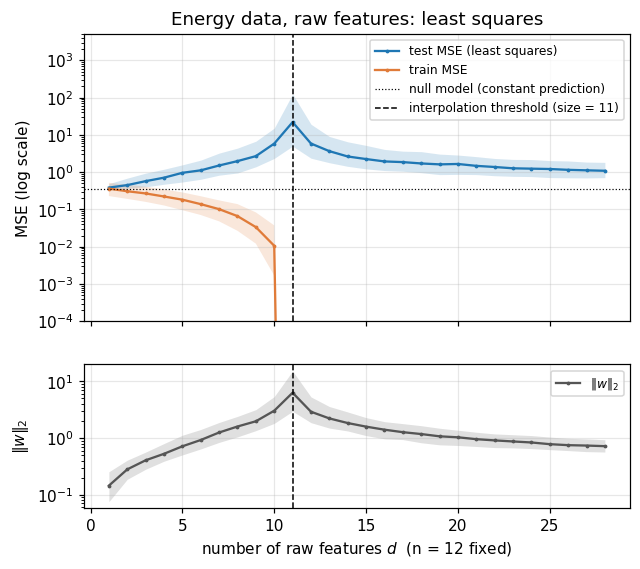

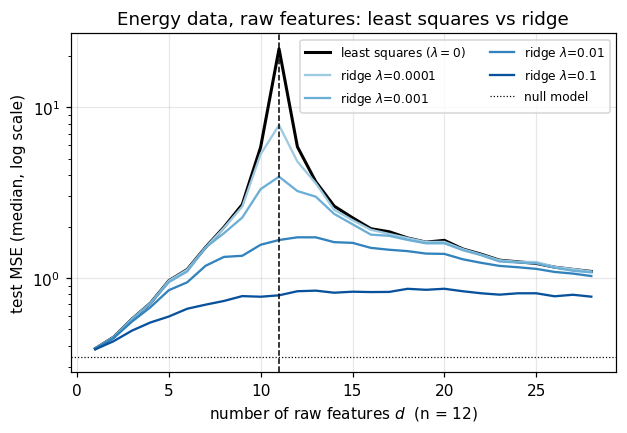

train MSE (median) around the threshold:
 size  train_median  test_median
    9  3.362502e-02     2.694115
   10  1.062309e-02     5.840229
   11  5.061777e-29    21.975266
   12  1.150194e-29     5.860342
   13  7.512356e-30     3.662449


In [78]:
RAW = dict(n=12, n_trials=300)
rng = rng_for("energy-raw")
rec = []
for t in range(RAW["n_trials"]):
    Xtr, ytr, Xte, yte, _ = energy_trial_data(rng, RAW["n"])
    order = rng.permutation(Xtr.shape[1])
    for d in range(1, Xtr.shape[1] + 1):
        cols_d = order[:d]
        w = fit_least_squares(Xtr[:, cols_d], ytr)
        wl = fit_ridge_path(Xtr[:, cols_d], ytr, np.array(RIDGE_LAMBDAS))
        r = dict(d=d, trial=t, train=mse(ytr, Xtr[:, cols_d] @ w), test=mse(yte, Xte[:, cols_d] @ w),
                 norm=np.linalg.norm(w), test_null=mse(yte, np.zeros_like(yte)))
        for lam, wv in zip(RIDGE_LAMBDAS, wl):
            r[f"test_ridge_{lam:g}"] = mse(yte, Xte[:, cols_d] @ wv)
        rec.append(r)
raw = summarise(rec, "d")
raw.to_csv(RES_DIR / "energy_raw.csv", index=False)

RAW_THR = RAW["n"] - 1       # centring X and y = fitting an intercept, which uses one of the n degrees of freedom
plot_double_descent(raw, RAW["n"], "number of raw features $d$  (n = 12 fixed)",
                    "Energy data, raw features: least squares", "fig3_energy_raw_ls",
                    null_level=raw["test_null_median"].iloc[0], threshold=RAW_THR)
plot_ridge(raw, RAW["n"], "number of raw features $d$  (n = 12)", "Energy data, raw features: least squares vs ridge",
           "fig4_energy_raw_ridge", RIDGE_LAMBDAS, null_level=raw["test_null_median"].iloc[0], threshold=RAW_THR)
summary_rows.append(key_numbers(raw, RAW["n"], "energy, raw features (n=12)", threshold=RAW_THR))
print("train MSE (median) around the threshold:")
print(raw[raw["size"].between(9, 13)][["size", "train_median", "test_median"]].to_string(index=False))

### 3.2 (b) Random Fourier features: realistic $n$, $N$ up to $10n$
Each new feature is built from the original 28 like this:
- Take a random weighted combination of the 28 inputs (the random weights are W),
- Add a random shift b, a number between 0 and 2pi,
- Take the cosine of the result,

The model is still
**linear in its parameters**: random features are created once and then fixed; nothing about them is learned. **Cosine vs. the paper's version:** the paper uses complex numbers, so each feature counts as 2 parameters. Using cosines keeps 1 feature = 1 parameter, so the threshold sits neatly at N = n = 500

- **500 training points, N from 5 to 5,000, 20 repetitions**. Each repetition uses a new training sample and new random features
- **nested features:** the 600-feature model is the 500-feature model plus 100 more. The curve shows the effect of adding features, not of reshuffling them
- **bandwidth:** how "wiggly" the cosines are. It's set to a typical distance between training points (the median distance), computed from training data only so no information leaks from the test set

In [79]:
RFF = dict(n=500, N_max=5000, n_trials=20, cv_trials=10)
RFF_SIZES = dense_grid(RFF["n"], RFF["N_max"], extra=(5, 10))
print(f"{len(RFF_SIZES)} values of N:", RFF_SIZES)


def median_pairwise_distance(X):
    sq = (X ** 2).sum(1)
    D2 = np.maximum(sq[:, None] + sq[None, :] - 2 * X @ X.T, 0)
    return float(np.median(np.sqrt(D2[np.triu_indices(len(X), k=1)])))


def rff_map(X, W, b):
    """phi(x) = sqrt(2/N) cos(W^T x + b), N = number of columns of W."""
    N = W.shape[1]
    return np.sqrt(2.0 / N) * np.cos(X @ W + b)


def gaussian_kernel(A, B, bw):
    sq = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T
    return np.exp(-np.maximum(sq, 0) / (2 * bw ** 2))


rng = rng_for("energy-rff")
rec, t = [], time.time()
for trial in range(RFF["n_trials"]):
    Xtr, ytr, Xte, yte, idx = energy_trial_data(rng, RFF["n"])
    bw = median_pairwise_distance(Xtr)
    W_all = rng.standard_normal((Xtr.shape[1], RFF["N_max"])) / bw
    b_all = rng.uniform(0, 2 * np.pi, RFF["N_max"])
    folds = np.array_split(np.argsort(idx), 5)       # contiguous-in-time CV folds inside the training sample
    # cos(W^T x + b) for all N_max features, computed once; the N-feature map is sqrt(2/N) * first N columns
    Ctr, Cte = np.cos(Xtr @ W_all + b_all), np.cos(Xte @ W_all + b_all)
    # N -> infinity limit: minimum-norm interpolation with the Gaussian kernel, alpha = K^+ y (paper's h_{n,inf})
    alpha = fit_least_squares(gaussian_kernel(Xtr, Xtr, bw), ytr)
    kernel_test = mse(yte, gaussian_kernel(Xte, Xtr, bw) @ alpha)
    for N in RFF_SIZES:
        Ftr, Fte = np.sqrt(2.0 / N) * Ctr[:, :N], np.sqrt(2.0 / N) * Cte[:, :N]
        svd = thin_svd(Ftr)
        w = fit_least_squares(Ftr, ytr, svd=svd)
        r = dict(N=N, trial=trial, train=mse(ytr, Ftr @ w), test=mse(yte, Fte @ w),
                 norm=np.linalg.norm(w), test_null=mse(yte, np.zeros_like(yte)), bandwidth=bw,
                 test_kernel_limit=kernel_test)
        for lam, wv in zip(RIDGE_LAMBDAS, fit_ridge_path(Ftr, ytr, np.array(RIDGE_LAMBDAS), svd=svd)):
            r[f"test_ridge_{lam:g}"] = mse(yte, Fte @ wv)
        if trial < RFF["cv_trials"]:
            wc, lam_c = fit_ridge_cv(Ftr, ytr, CV_LAMBDAS, folds)
            r["test_ridge_cv"], r["lambda_cv"] = mse(yte, Fte @ wc), lam_c
        rec.append(r)
    print(f"  trial {trial+1}/{RFF['n_trials']} done ({time.time()-t:.0f}s)", end="\r")
rff = summarise(rec, "N")
rff.to_csv(RES_DIR / "energy_rff.csv", index=False)
print(f"\nRFF sweep: {len(RFF_SIZES)} sizes x {RFF['n_trials']} trials in {time.time()-t:.0f}s")

# classical reference: OLS on the 28 raw features with the same n = 500
rng = rng_for("energy-ols-ref")
ols_ref = []
for trial in range(RFF["n_trials"]):
    Xtr, ytr, Xte, yte, _ = energy_trial_data(rng, RFF["n"])
    ols_ref.append(mse(yte, Xte @ fit_least_squares(Xtr, ytr)))
OLS_REF = float(np.median(ols_ref))
print(f"reference: linear OLS on 28 raw features, n=500 -> median test MSE {OLS_REF:.3f}")

52 values of N: [   1    2    3    4    5    6    8   10   14   19   25   34   46   61
   82  110  147  198  265  356  400  410  420  430  440  450  460  470
  477  480  490  499  500  501  510  520  530  540  550  560  570  580
  590  600  640  858 1151 1544 2072 2779 3728 5000]
  trial 20/20 done (263s)
RFF sweep: 52 sizes x 20 trials in 263s
reference: linear OLS on 28 raw features, n=500 -> median test MSE 0.305


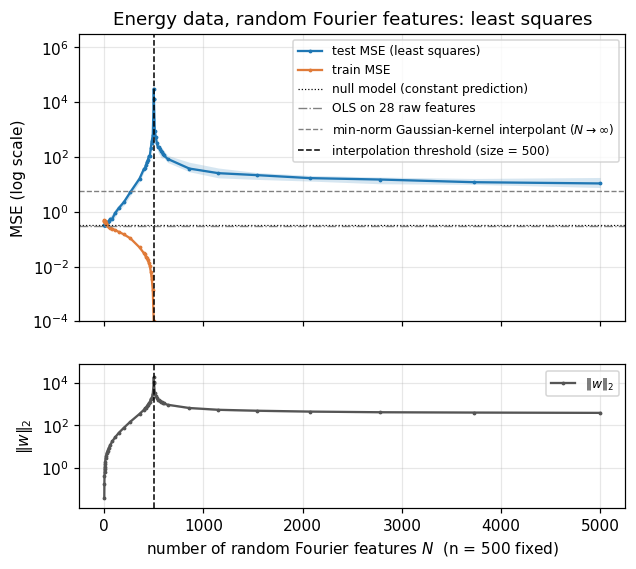

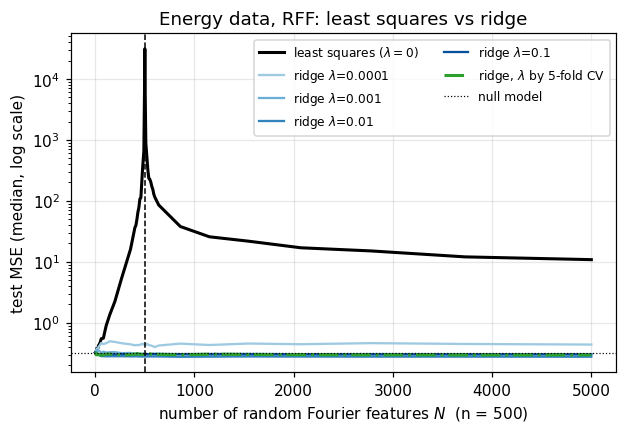

 size  train_median  test_median  test_ridge_cv_median  lambda_cv_median
   10        0.4091       0.3406                0.3053            0.0100
  500        0.0000   31170.4799                0.3066            0.0018
 5000        0.0000      10.8496                0.2974            0.0018
kernel limit (N -> inf), median test MSE: 5.9680


In [80]:
plot_double_descent(rff, RFF["n"], "number of random Fourier features $N$  (n = 500 fixed)",
                    "Energy data, random Fourier features: least squares", "fig5_energy_rff_ls",
                    null_level=rff["test_null_median"].iloc[0],
                    extra_hlines=[(OLS_REF, "OLS on 28 raw features", "-."),
                                  (rff["test_kernel_limit_median"].iloc[0], "min-norm Gaussian-kernel interpolant ($N\\to\\infty$)", "--")])
plot_ridge(rff, RFF["n"], "number of random Fourier features $N$  (n = 500)",
           "Energy data, RFF: least squares vs ridge", "fig6_energy_rff_ridge", RIDGE_LAMBDAS,
           null_level=rff["test_null_median"].iloc[0])
summary_rows.append(key_numbers(rff, RFF["n"], "energy, RFF (n=500)"))
print(rff[rff["size"].isin([10, 100, 250, 500, 1000, 5000])][
      ["size", "train_median", "test_median", "test_ridge_cv_median", "lambda_cv_median"]].round(4).to_string(index=False))
print(f"kernel limit (N -> inf), median test MSE: {rff['test_kernel_limit_median'].iloc[0]:.4f}")

## 4. Extensions
### 4.1 Gradient descent vs closed form
1. **Where gradient descent ends up (starting from zero)**
- Each step only moves the weights in directions built from the training data.
- When d > n, there are infinitely many weight vectors that fit the training data perfectly. Of those, only one can be reached by moving in "data directions": the smallest-norm solution, the same one the exact formula gives.
- So gradient descent started at zero automatically picks the minimum-norm solution, with no extra rule needed. This is called its implicit bias.
- If you start from random weights instead, the part of the starting point that the data can't see is never changed. You still fit the training data perfectly, but with larger weights and usually a worse test error.

2. **What happens if you stop early**
- Near d = n, some directions in the data are very weak, meaning very small singular values. Gradient descent learns them extremely slowly.
- Those weak directions are exactly what causes the peak, because fitting them means fitting noise.
- If you stop after T steps, gradient descent never fully fits them. That has the same effect as ridge, so the peak gets flattened.

Note: right around d = n, even 10,000 steps aren't enough to finish. So the gradient-descent results there, including the random-start ones, are "stopped early" rather than exact solutions.

GD experiment in 80s


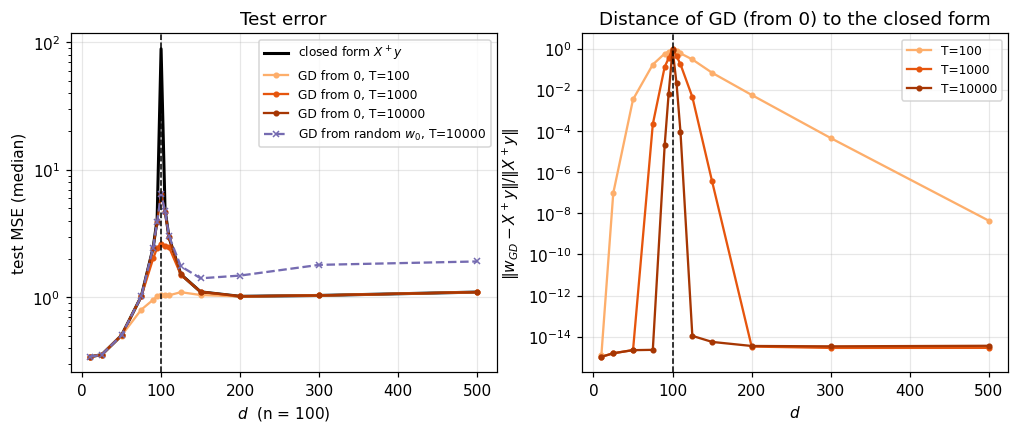

 size  norm_median  norm_gd_rand_median  test_median  test_gd_rand_median  train_gd_rand_median
  105       2.4204               2.2419       4.8757               4.7694                   0.0
  110       1.8826               1.9000       2.9590               3.0278                   0.0
  125       1.3624               1.4528       1.5175               1.7548                   0.0
  150       1.0707               1.2265       1.1070               1.4133                   0.0
  200       0.8591               1.1045       1.0208               1.4848                   0.0
  300       0.6790               1.0620       1.0373               1.8016                   0.0
  500       0.5104               1.0290       1.1026               1.9159                   0.0


In [81]:
GD = dict(n_trials=20, iters=(100, 1000, 10000), d_grid=np.array([10, 25, 50, 75, 90, 95, 100, 105, 110, 125, 150, 200, 300, 500]))
rng = rng_for("gd")
rec, t = [], time.time()
for trial in range(GD["n_trials"]):
    Xtr, ytr, Xte, yte, _ = make_synthetic(rng, SYN["n"], SYN["n_test"], SYN["D"], SYN["sigma"])
    for d in GD["d_grid"]:
        A, B = Xtr[:, :d], Xte[:, :d]
        w_cf = fit_least_squares(A, ytr)
        _, snaps = fit_gradient_descent(A, ytr, max(GD["iters"]), record_at=GD["iters"])
        w0 = rng.standard_normal(d) / np.sqrt(d)          # random init with E||w0||^2 = 1
        w_rand, _ = fit_gradient_descent(A, ytr, max(GD["iters"]), w0=w0)
        r = dict(d=d, trial=trial, test=mse(yte, B @ w_cf), norm=np.linalg.norm(w_cf),
                 test_gd_rand=mse(yte, B @ w_rand), norm_gd_rand=np.linalg.norm(w_rand),
                 train_gd_rand=mse(ytr, A @ w_rand))
        for T in GD["iters"]:
            r[f"test_gd_{T}"] = mse(yte, B @ snaps[T])
            r[f"train_gd_{T}"] = mse(ytr, A @ snaps[T])
            r[f"dist_gd_{T}"] = np.linalg.norm(snaps[T] - w_cf) / np.linalg.norm(w_cf)
        rec.append(r)
gd = summarise(rec, "d")
gd.to_csv(RES_DIR / "gd_vs_closed_form.csv", index=False)
print(f"GD experiment in {time.time()-t:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = gd["size"]
axes[0].plot(x, gd["test_median"], color="k", lw=2, label="closed form $X^+y$")
for T, col in zip(GD["iters"], ["#fdae6b", "#e6550d", "#a63603"]):
    axes[0].plot(x, gd[f"test_gd_{T}_median"], color=col, marker=".", label=f"GD from 0, T={T}")
axes[0].plot(x, gd["test_gd_rand_median"], color="#756bb1", ls="--", marker="x", ms=4,
             label=f"GD from random $w_0$, T={max(GD['iters'])}")
axes[0].set_yscale("log"); axes[0].set_xlabel("$d$  (n = 100)"); axes[0].set_ylabel("test MSE (median)")
axes[0].set_title("Test error"); axes[0].axvline(SYN["n"], color="k", ls="--", lw=1); axes[0].legend()
for T, col in zip(GD["iters"], ["#fdae6b", "#e6550d", "#a63603"]):
    axes[1].plot(x, gd[f"dist_gd_{T}_median"], color=col, marker=".", label=f"T={T}")
axes[1].set_yscale("log"); axes[1].set_xlabel("$d$"); axes[1].axvline(SYN["n"], color="k", ls="--", lw=1)
axes[1].set_ylabel(r"$\|w_{GD}-X^+y\|/\|X^+y\|$"); axes[1].set_title("Distance of GD (from 0) to the closed form")
axes[1].legend()
savefig(fig, "fig7_gd_vs_closed_form"); plt.show()

print(gd[gd["size"] > SYN["n"]][["size", "norm_median", "norm_gd_rand_median", "test_median",
                                  "test_gd_rand_median", "train_gd_rand_median"]].round(4).to_string(index=False))

### 4.2 Effect of label noise
Same synthetic protocol with $\sigma\in\{0, 0.25, 0.5, 1\}$. For $\sigma=0$ the labels are a deterministic
linear function of all $D$ features; the peak can still appear because the $D-d$ omitted features act as noise
for the $d$-feature model (cf. the paper's SNR $=\infty$ case, Fig. 10).

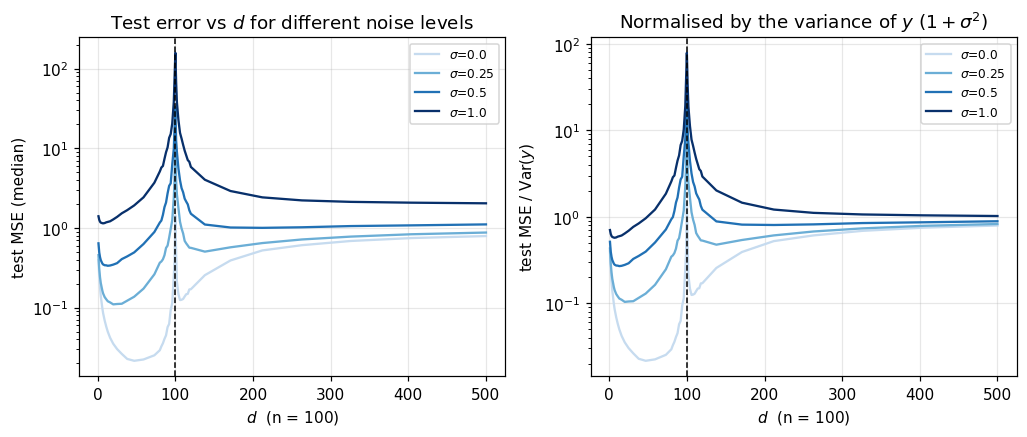

,dataset,best_underparam_size,best_underparam_test,test_at_threshold,largest_size,test_at_largest,overall_best_size,overall_best_test
0,synthetic sigma=0.0,47,0.0216,1.4233,500,0.7935,47,0.0216
1,synthetic sigma=0.25,20,0.1102,14.8271,500,0.8781,20,0.1102
2,synthetic sigma=0.5,13,0.3362,33.2356,500,1.1112,13,0.3362
3,synthetic sigma=1.0,7,1.1457,158.3148,500,2.0443,7,1.1457


In [82]:
NOISE_LEVELS = [0.0, 0.25, 0.5, 1.0]
noise_res = {sg: synthetic_sweep(sg, SYN_SIZES, seed_name="noise") for sg in NOISE_LEVELS}
pd.concat([s.assign(sigma=sg) for sg, s in noise_res.items()]).to_csv(RES_DIR / "noise.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for sg, col in zip(NOISE_LEVELS, ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]):
    s = noise_res[sg]
    axes[0].plot(s["size"], s["test_median"], color=col, label=f"$\\sigma$={sg}")
    axes[1].plot(s["size"], s["test_median"] / (1 + sg ** 2), color=col, label=f"$\\sigma$={sg}")
for ax in axes:
    ax.set_yscale("log"); ax.axvline(SYN["n"], color="k", ls="--", lw=1); ax.set_xlabel("$d$  (n = 100)"); ax.legend()
axes[0].set_ylabel("test MSE (median)"); axes[0].set_title("Test error vs $d$ for different noise levels")
axes[1].set_ylabel(r"test MSE / Var$(y)$"); axes[1].set_title("Normalised by the variance of $y$ ($1+\\sigma^2$)")
savefig(fig, "fig8_noise"); plt.show()

noise_tab = pd.DataFrame([{**key_numbers(noise_res[sg], SYN["n"], f"synthetic sigma={sg}")} for sg in NOISE_LEVELS])
noise_tab.round(4)

## 5. Comparison across datasets
To put the three experiments on one scale, the x-axis is the number of parameters divided by $n$ (threshold at 1;
for the raw-feature model the intercept counts as a parameter, see 3.1) and the y-axis is test MSE divided by the MSE of the null model (1 = no better than predicting the training mean).

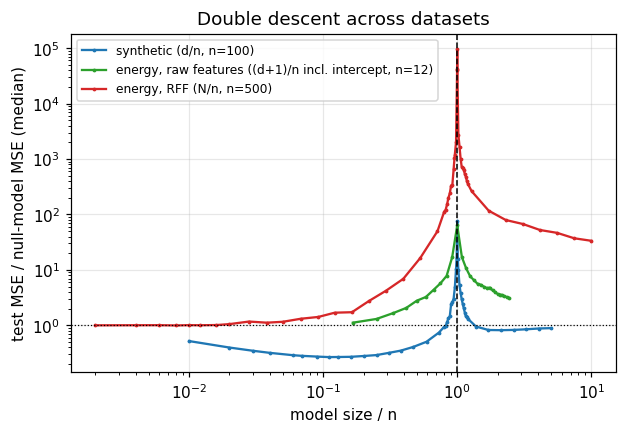

                        dataset  best_underparam_size  best_underparam_test  test_at_threshold  largest_size  test_at_largest  overall_best_size  overall_best_test
          synthetic (sigma=0.5)                    11                0.3350            95.0371           500           1.1150                 11             0.3350
synthetic flat beta (sigma=0.5)                     1                1.2572           498.6070           500           1.1076                500             1.1076
    energy, raw features (n=12)                     1                0.3856            21.9753            28           1.0911                  1             0.3856
            energy, RFF (n=500)                     4                0.3222         31170.4799          5000          10.8496                  4             0.3222

Total runtime: 403s


In [83]:
fig, ax = plt.subplots(figsize=(6.4, 4))
for s, n, lab, col in [(syn, SYN["n"], "synthetic (d/n, n=100)", "#1F77B4"),
                        (raw.assign(size=raw["size"] + 1), RAW["n"], "energy, raw features ((d+1)/n incl. intercept, n=12)", "#2ca02c"),
                       (rff, RFF["n"], "energy, RFF (N/n, n=500)", "#d62728")]:
    ax.plot(s["size"] / n, s["test_median"] / s["test_null_median"], color=col, marker=".", ms=3, label=lab)
ax.axvline(1, color="k", ls="--", lw=1); ax.axhline(1, color="k", ls=":", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("model size / n"); ax.set_ylabel("test MSE / null-model MSE (median)")
ax.set_title("Double descent across datasets"); ax.legend()
savefig(fig, "fig9_comparison"); plt.show()

summary = pd.DataFrame(summary_rows)
summary.to_csv(RES_DIR / "summary.csv", index=False)
print(summary.round(4).to_string(index=False))
print(f"\nTotal runtime: {time.time() - T0:.0f}s")

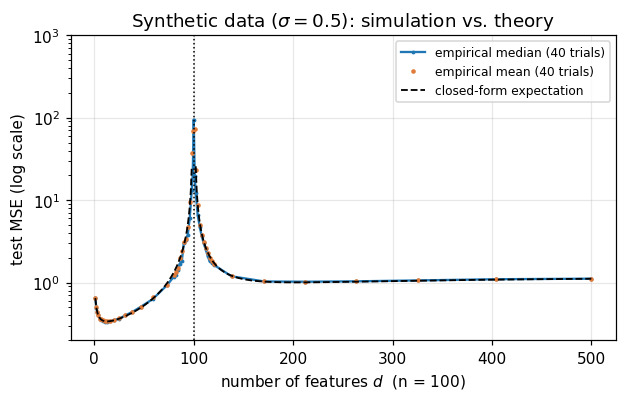

 size  test_median  test_mean  theory
    1       0.6517     0.6522  0.6479
   11       0.3350     0.3411  0.3394
   90       2.9943     3.0918  2.8106
  110       3.0077     3.1353  3.1703
  212       1.0244     1.0172  1.0058
  500       1.1150     1.1186  1.1127


In [ ]:
# 2.5 Agreement with theory (Belkin, Hsu & Xu 2020): closed-form expected test MSE
# for an isotropic Gaussian design when the model uses the first d of D features
n, D, sigma = SYN["n"], SYN["D"], SYN["sigma"]
b2 = 1 / np.arange(1, D + 1) ** 2
b2 /= b2.sum()    # beta_j^2 (the signs don't matter)

def theory_risk(d):
    sS, sR = b2[:d].sum(), b2[d:].sum()  # ||beta_S||^2, ||beta_{S^c}||^2
    if d <= n - 2:
        return (sigma**2 + sR) * (1 + d / (n - d - 1))
    if d >= n + 2:
        return sS * (1 - n / d) + (sigma**2 + sR) * (1 + n / (d - n - 1))
    return np.nan  # expectation is infinite for n-1 <= d <= n+1

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(syn["size"], syn["test_median"], ".-", color=C_TEST, ms=3, label="empirical median (40 trials)")
ax.plot(syn["size"], syn["test_mean"], ".", color=C_TRAIN, ms=4, label="empirical mean (40 trials)")
dd = np.arange(1, D + 1)
ax.plot(dd, [theory_risk(d) for d in dd], color="k", lw=1.2, ls="--", label="closed-form expectation")
ax.axvline(n, color="k", ls=":", lw=1)
ax.set_yscale("log"); ax.set_ylim(0.2, 1e3)
ax.set_xlabel("number of features $d$  (n = 100)"); ax.set_ylabel("test MSE (log scale)")
ax.set_title(r"Synthetic data ($\sigma=0.5$): simulation vs. theory"); ax.legend()
savefig(fig, "fig10_theory"); plt.show()

check = syn[["size", "test_median", "test_mean"]].copy()
check["theory"] = [theory_risk(int(d)) for d in check["size"]]
check.to_csv(RES_DIR / "theory_check.csv", index=False)
print(check[check["size"].isin([1, 11, 90, 110, 212, 500])].round(4).to_string(index=False))